In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# UCITAVANJE PODATAKA
# ------------------------------------------------------------

df = pd.read_csv("cars.csv")

print("Dimenzije dataseta:")
print(df.shape)

print("\nNazivi kolona:")
print(df.columns.tolist())

print("\nPrvih 5 redova:")
display(df.head())

print("\nTipovi podataka:")
print(df.dtypes)

print("\nNedostajuce vrednosti:")
print(df.isnull().sum())

Dimenzije dataseta:
(56244, 12)

Nazivi kolona:
['make', 'model', 'priceUSD', 'year', 'condition', 'mileage(kilometers)', 'fuel_type', 'volume(cm3)', 'color', 'transmission', 'drive_unit', 'segment']

Prvih 5 redova:


,make,model,priceUSD,year,condition,mileage(kilometers),fuel_type,volume(cm3),color,transmission,drive_unit,segment
0,mazda,2,5500,2008,with mileage,162000.0,petrol,1500.0,burgundy,mechanics,front-wheel drive,B
1,mazda,2,5350,2009,with mileage,120000.0,petrol,1300.0,black,mechanics,front-wheel drive,B
2,mazda,2,7000,2009,with mileage,61000.0,petrol,1500.0,silver,auto,front-wheel drive,B
3,mazda,2,3300,2003,with mileage,265000.0,diesel,1400.0,white,mechanics,front-wheel drive,B
4,mazda,2,5200,2008,with mileage,97183.0,diesel,1400.0,gray,mechanics,front-wheel drive,B



Tipovi podataka:
make                       str
model                      str
priceUSD                 int64
year                     int64
condition                  str
mileage(kilometers)    float64
fuel_type                  str
volume(cm3)            float64
color                      str
transmission               str
drive_unit                 str
segment                    str
dtype: object

Nedostajuce vrednosti:
make                      0
model                     0
priceUSD                  0
year                      0
condition                 0
mileage(kilometers)       0
fuel_type                 0
volume(cm3)              47
color                     0
transmission              0
drive_unit             1905
segment                5291
dtype: int64


In [3]:
# ------------------------------------------------------------
# OSNOVNA STATISTIKA NUMERICKIH KOLONA
# ------------------------------------------------------------

numeric_columns = [
    "priceUSD",
    "year",
    "mileage(kilometers)",
    "volume(cm3)"
]

print("Osnovna statistika:")
display(
    df[numeric_columns].describe()
)

print("\nMinimalne vrednosti:")
print(df[numeric_columns].min())

print("\nMaksimalne vrednosti:")
print(df[numeric_columns].max())

print("\nBroj jedinstvenih vrednosti:")
print(df[numeric_columns].nunique())

Osnovna statistika:


,priceUSD,year,mileage(kilometers),volume(cm3)
count,56244.000000,56244.000000,5.624400e+04,56197.000000
mean,7415.456440,2003.454840,2.443956e+05,2104.860615
std,8316.959261,8.144247,3.210307e+05,959.201633
min,48.000000,1910.000000,0.000000e+00,500.000000
25%,2350.000000,1998.000000,1.370000e+05,1600.000000
50%,5350.000000,2004.000000,2.285000e+05,1996.000000
75%,9807.500000,2010.000000,3.100000e+05,2300.000000
max,235235.000000,2019.000000,9.999999e+06,20000.000000



Minimalne vrednosti:
priceUSD                 48.0
year                   1910.0
mileage(kilometers)       0.0
volume(cm3)             500.0
dtype: float64

Maksimalne vrednosti:
priceUSD                235235.0
year                      2019.0
mileage(kilometers)    9999999.0
volume(cm3)              20000.0
dtype: float64

Broj jedinstvenih vrednosti:
priceUSD               2970
year                     78
mileage(kilometers)    8400
volume(cm3)             458
dtype: int64


In [4]:
# ------------------------------------------------------------
# PROVERA SUMNJIVIH I EKSTREMNIH VREDNOSTI
# ------------------------------------------------------------

print("Cena <= 100 USD:")
print((df["priceUSD"] <= 100).sum())

print("\nCena >= 100000 USD:")
print((df["priceUSD"] >= 100000).sum())

print("\nGodina < 1950:")
print((df["year"] < 1950).sum())

print("\nKilometraza = 0:")
print((df["mileage(kilometers)"] == 0).sum())

print("\nKilometraza > 1,000,000 km:")
print((df["mileage(kilometers)"] > 1_000_000).sum())

print("\nZapremina motora > 8000 cm3:")
print((df["volume(cm3)"] > 8000).sum())


print("\n--- Najjeftiniji automobili ---")
display(
    df.nsmallest(10, "priceUSD")[
        [
            "make",
            "model",
            "priceUSD",
            "year",
            "mileage(kilometers)",
            "volume(cm3)"
        ]
    ]
)

print("\n--- Najveca kilometraza ---")
display(
    df.nlargest(10, "mileage(kilometers)")[
        [
            "make",
            "model",
            "priceUSD",
            "year",
            "mileage(kilometers)",
            "volume(cm3)"
        ]
    ]
)

print("\n--- Najveca zapremina motora ---")
display(
    df.nlargest(10, "volume(cm3)")[
        [
            "make",
            "model",
            "priceUSD",
            "year",
            "mileage(kilometers)",
            "volume(cm3)"
        ]
    ]
)

Cena <= 100 USD:
9

Cena >= 100000 USD:
33

Godina < 1950:
8

Kilometraza = 0:
190

Kilometraza > 1,000,000 km:
364

Zapremina motora > 8000 cm3:
88

--- Najjeftiniji automobili ---


,make,model,priceUSD,year,mileage(kilometers),volume(cm3)
5952,zaz,968,48,1910,25000.0,1100.0
40252,proton,persona,95,1997,1111.0,1600.0
5456,mazda,626,100,1986,100.0,2000.0
7314,mercedes-benz,190-w201,100,1991,2000.0,2000.0
20971,toyota,corolla,100,1988,300000.0,1300.0
23898,ford,escort,100,1986,200000.0,1300.0
24873,ford,fiesta,100,1992,1.0,1100.0
41010,nissan,primera,100,1994,300000.0,2000.0
54171,citroen,xantia,100,1995,380000.0,1800.0
7076,lada-vaz,21099,119,1992,20000.0,1500.0



--- Najveca kilometraza ---


,make,model,priceUSD,year,mileage(kilometers),volume(cm3)
1394,audi,80,500,1986,9999999.0,1800.0
1854,audi,100,900,1989,9999999.0,2300.0
5783,peugeot,806,4100,2000,9999999.0,2000.0
6114,lada-vaz,2104,600,1990,9999999.0,1500.0
6465,lada-vaz,2108,295,1990,9999999.0,1100.0
6684,raf,2203,1000,1991,9999999.0,2400.0
10032,bmw,5-seriya,2000,1985,9999999.0,2800.0
10316,bmw,7-seriya,4650,1998,9999999.0,3000.0
11699,audi,a4,3000,1996,9999999.0,1800.0
16705,fiat,brava,1100,1997,9999999.0,1400.0



--- Najveca zapremina motora ---


,make,model,priceUSD,year,mileage(kilometers),volume(cm3)
81,mazda,3,5300,2006,168000.0,20000.0
354,mazda,6,7500,2003,240000.0,20000.0
1537,audi,80,2900,1993,392432.0,20000.0
1768,audi,100,2150,1992,300000.0,20000.0
4573,peugeot,407,4600,2004,262900.0,20000.0
4816,volvo,460,750,1994,333000.0,20000.0
5369,mazda,626,1200,1995,425326.0,20000.0
5553,mazda,626,1000,1990,250000.0,20000.0
5607,mazda,626,1200,1989,0.0,20000.0
5908,volvo,940,1521,1997,300000.0,20000.0


Kvantili cene:
0.00        48.0
0.01       333.0
0.05       700.0
0.10      1050.0
0.25      2350.0
0.50      5350.0
0.75      9807.5
0.90     15250.0
0.95     20000.0
0.99     39728.5
1.00    235235.0
Name: priceUSD, dtype: float64

10 najskupljih automobila:


,make,model,priceUSD,year,condition,mileage(kilometers),fuel_type,volume(cm3)
20787,bentley,continental-gt,235235,2018,with mileage,29000.0,petrol,6000.0
16430,bentley,bentayga,195000,2016,with mileage,72000.0,petrol,6000.0
35457,bentley,mulsanne,190141,2014,with mileage,36500.0,petrol,6750.0
16428,bentley,bentayga,183848,2016,with mileage,22000.0,petrol,6000.0
16429,bentley,bentayga,170477,2016,with mileage,74100.0,petrol,6000.0
19557,porsche,cayenne,170000,2018,with mileage,1020.0,petrol,4000.0
34508,tesla,model-x,161563,2019,with mileage,50.0,electrocar,NaN
26254,mercedes-benz,g-klass,150000,2001,with mileage,160000.0,petrol,5000.0
33702,mercedes-benz,maybach,148000,2019,with mileage,950.0,petrol,3000.0
33327,bmw,m5,128136,2019,with mileage,2925.0,petrol,4400.0


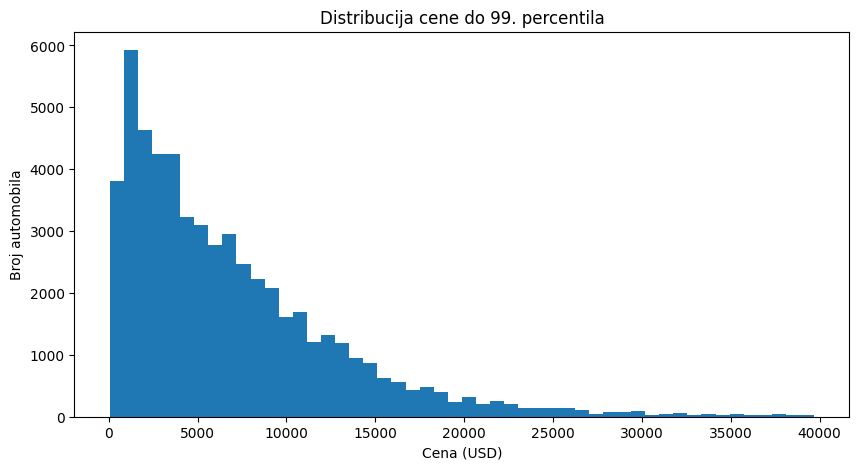

In [5]:
# ------------------------------------------------------------
# DETALJNIJA ANALIZA CILJNE PROMENLJIVE priceUSD
# ------------------------------------------------------------

print("Kvantili cene:")
print(
    df["priceUSD"].quantile([
        0.00,
        0.01,
        0.05,
        0.10,
        0.25,
        0.50,
        0.75,
        0.90,
        0.95,
        0.99,
        1.00
    ])
)

print("\n10 najskupljih automobila:")
display(
    df.nlargest(10, "priceUSD")[
        [
            "make",
            "model",
            "priceUSD",
            "year",
            "condition",
            "mileage(kilometers)",
            "fuel_type",
            "volume(cm3)"
        ]
    ]
)

# Histogram cene do 99. percentila
price_limit = df["priceUSD"].quantile(0.99)

plt.figure(figsize=(10, 5))

plt.hist(
    df.loc[
        df["priceUSD"] <= price_limit,
        "priceUSD"
    ],
    bins=50
)

plt.xlabel("Cena (USD)")
plt.ylabel("Broj automobila")
plt.title("Distribucija cene do 99. percentila")

plt.show()

In [6]:
# ------------------------------------------------------------
# ANALIZA KATEGORIJSKIH KOLONA I DUPLIKATA
# ------------------------------------------------------------

categorical_columns = [
    "make",
    "model",
    "condition",
    "fuel_type",
    "color",
    "transmission",
    "drive_unit",
    "segment"
]

print("Broj jedinstvenih vrednosti:")
for col in categorical_columns:
    print(f"{col}: {df[col].nunique(dropna=False)}")


print("\nBroj potpuno dupliranih redova:")
print(df.duplicated().sum())


for col in [
    "condition",
    "fuel_type",
    "transmission",
    "drive_unit",
    "segment"
]:
    print("\n" + "=" * 60)
    print(col.upper())
    print("=" * 60)

    print(
        df[col]
        .value_counts(
            dropna=False
        )
        .head(20)
    )

Broj jedinstvenih vrednosti:
make: 96
model: 1034
condition: 3
fuel_type: 3
color: 13
transmission: 2
drive_unit: 5
segment: 10

Broj potpuno dupliranih redova:
87

CONDITION
condition
with mileage    55278
with damage       512
for parts         454
Name: count, dtype: int64

FUEL_TYPE
fuel_type
petrol        36405
diesel        19792
electrocar       47
Name: count, dtype: int64

TRANSMISSION
transmission
mechanics    36056
auto         20188
Name: count, dtype: int64

DRIVE_UNIT
drive_unit
front-wheel drive             38016
rear drive                     6836
all-wheel drive                5890
part-time four-wheel drive     3597
NaN                            1905
Name: count, dtype: int64

SEGMENT
segment
D      12605
C      10617
J       8629
M       6313
E       6274
NaN     5291
B       4393
F        896
S        765
A        461
Name: count, dtype: int64


In [7]:
# ------------------------------------------------------------
# PREGLED SVIH VREDNOSTI U KATEGORIJSKIM KOLONAMA
# ------------------------------------------------------------

for col in [
    "fuel_type",
    "transmission",
    "drive_unit",
    "segment"
]:
    print("\n" + "=" * 60)
    print(col.upper())
    print("=" * 60)

    display(
        df[col]
        .value_counts(dropna=False)
        .reset_index()
    )


FUEL_TYPE


,fuel_type,count
0,petrol,36405
1,diesel,19792
2,electrocar,47



TRANSMISSION


,transmission,count
0,mechanics,36056
1,auto,20188



DRIVE_UNIT


,drive_unit,count
0,front-wheel drive,38016
1,rear drive,6836
2,all-wheel drive,5890
3,part-time four-wheel drive,3597
4,NaN,1905



SEGMENT


,segment,count
0,D,12605
1,C,10617
2,J,8629
3,M,6313
4,E,6274
5,NaN,5291
6,B,4393
7,F,896
8,S,765
9,A,461


In [8]:
# ------------------------------------------------------------
# OSNOVNO CISCENJE PODATAKA
# ------------------------------------------------------------

df_clean = df.copy()

print("Broj redova pre ciscenja:", len(df_clean))


# 1. Uklanjanje potpuno dupliranih redova
df_clean = df_clean.drop_duplicates().copy()


# 2. Ekstremno velike kilometraze tretiramo kao nevalidne
df_clean.loc[
    df_clean["mileage(kilometers)"] > 1_000_000,
    "mileage(kilometers)"
] = np.nan


# 3. Ekstremno velike zapremine motora tretiramo kao nevalidne
df_clean.loc[
    df_clean["volume(cm3)"] > 8000,
    "volume(cm3)"
] = np.nan


print("Broj redova posle uklanjanja duplikata:", len(df_clean))

print("\nNedostajuce vrednosti nakon ciscenja:")
print(df_clean.isnull().sum())

print("\nRaspon kilometraze nakon ciscenja:")
print(
    df_clean["mileage(kilometers)"].min(),
    "-",
    df_clean["mileage(kilometers)"].max()
)

print("\nRaspon zapremine motora nakon ciscenja:")
print(
    df_clean["volume(cm3)"].min(),
    "-",
    df_clean["volume(cm3)"].max()
)

Broj redova pre ciscenja: 56244
Broj redova posle uklanjanja duplikata: 56157

Nedostajuce vrednosti nakon ciscenja:
make                      0
model                     0
priceUSD                  0
year                      0
condition                 0
mileage(kilometers)     363
fuel_type                 0
volume(cm3)             135
color                     0
transmission              0
drive_unit             1904
segment                5285
dtype: int64

Raspon kilometraze nakon ciscenja:
0.0 - 1000000.0

Raspon zapremine motora nakon ciscenja:
500.0 - 8000.0


In [9]:
# ------------------------------------------------------------
# FEATURE ENGINEERING
# ------------------------------------------------------------

df_features = df_clean.copy()

REFERENCE_YEAR = df_features["year"].max() + 1

print("Referentna godina:", REFERENCE_YEAR)


# 1. Starost automobila
df_features["car_age"] = (
    REFERENCE_YEAR - df_features["year"]
)


# 2. Prosecna kilometraza po godini
df_features["mileage_per_year"] = (
    df_features["mileage(kilometers)"]
    / df_features["car_age"].clip(lower=1)
)


# 3. Zapremina motora u litrima
df_features["engine_volume_liters"] = (
    df_features["volume(cm3)"] / 1000
)


# 4. Kombinacija marke i modela
df_features["brand_model"] = (
    df_features["make"].astype(str)
    + "_"
    + df_features["model"].astype(str)
)


print("\nNove karakteristike:")
display(
    df_features[
        [
            "make",
            "model",
            "year",
            "car_age",
            "mileage(kilometers)",
            "mileage_per_year",
            "volume(cm3)",
            "engine_volume_liters",
            "brand_model",
            "priceUSD"
        ]
    ].head(10)
)


print("\nStatistika novih numerickih karakteristika:")
display(
    df_features[
        [
            "car_age",
            "mileage_per_year",
            "engine_volume_liters"
        ]
    ].describe()
)

print("\nBroj jedinstvenih brand_model vrednosti:")
print(
    df_features["brand_model"].nunique()
)

Referentna godina: 2020

Nove karakteristike:


,make,model,year,car_age,mileage(kilometers),mileage_per_year,volume(cm3),engine_volume_liters,brand_model,priceUSD
0,mazda,2,2008,12,162000.0,13500.000000,1500.0,1.5,mazda_2,5500
1,mazda,2,2009,11,120000.0,10909.090909,1300.0,1.3,mazda_2,5350
2,mazda,2,2009,11,61000.0,5545.454545,1500.0,1.5,mazda_2,7000
3,mazda,2,2003,17,265000.0,15588.235294,1400.0,1.4,mazda_2,3300
4,mazda,2,2008,12,97183.0,8098.583333,1400.0,1.4,mazda_2,5200
5,mazda,2,2005,15,150000.0,10000.000000,1300.0,1.3,mazda_2,3400
6,mazda,2,2008,12,112000.0,9333.333333,1300.0,1.3,mazda_2,5000
7,mazda,2,2009,11,95000.0,8636.363636,1500.0,1.5,mazda_2,7300
8,mazda,2,2010,10,93804.0,9380.400000,1500.0,1.5,mazda_2,6400
9,mazda,2,2008,12,196511.0,16375.916667,1500.0,1.5,mazda_2,6132



Statistika novih numerickih karakteristika:


,car_age,mileage_per_year,engine_volume_liters
count,56157.000000,55794.000000,56022.000000
mean,16.543441,15292.398032,2.080159
std,8.145438,7967.781759,0.720141
min,1.000000,0.000000,0.500000
25%,10.000000,11125.000000,1.600000
50%,16.000000,15000.000000,1.995000
75%,22.000000,19166.666667,2.300000
max,110.000000,330000.000000,8.000000



Broj jedinstvenih brand_model vrednosti:
1071


In [10]:
# ------------------------------------------------------------
# PRIPREMA PODATAKA ZA MODEL
# ------------------------------------------------------------

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


# Ciljna promenljiva
y = df_features["priceUSD"]


# Numericke karakteristike
numeric_features = [
    "car_age",
    "mileage(kilometers)",
    "mileage_per_year",
    "engine_volume_liters"
]


# Kategorijske karakteristike
categorical_features = [
    "make",
    "model",
    "brand_model",
    "condition",
    "fuel_type",
    "color",
    "transmission",
    "drive_unit",
    "segment"
]


# Ulazni podaci
X = df_features[
    numeric_features
    + categorical_features
].copy()


# ------------------------------------------------------------
# TRAIN / TEST PODELA
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


# ------------------------------------------------------------
# NUMERICKI PIPELINE
# ------------------------------------------------------------

numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)


# ------------------------------------------------------------
# KATEGORIJSKI PIPELINE
# ------------------------------------------------------------

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)


# ------------------------------------------------------------
# KOMPLETAN PREPROCESSOR
# ------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)


print("\nNumericke karakteristike:")
print(numeric_features)

print("\nKategorijske karakteristike:")
print(categorical_features)

X_train: (44925, 13)
X_test: (11232, 13)
y_train: (44925,)
y_test: (11232,)

Numericke karakteristike:
['car_age', 'mileage(kilometers)', 'mileage_per_year', 'engine_volume_liters']

Kategorijske karakteristike:
['make', 'model', 'brand_model', 'condition', 'fuel_type', 'color', 'transmission', 'drive_unit', 'segment']


In [11]:
# ------------------------------------------------------------
# BASELINE MODEL - LINEAR REGRESSION
# ------------------------------------------------------------

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Pipeline = preprocessing + model
linear_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            LinearRegression()
        )
    ]
)


print("Treniranje Linear Regression modela...")

linear_model.fit(
    X_train,
    y_train
)


# Predikcije
linear_predictions = linear_model.predict(
    X_test
)


# Evaluacija
linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_mse = mean_squared_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    linear_mse
)

linear_r2 = r2_score(
    y_test,
    linear_predictions
)


print("\nLinear Regression rezultati:")
print(
    "MAE:",
    round(linear_mae, 2)
)
print(
    "MSE:",
    round(linear_mse, 2)
)
print(
    "RMSE:",
    round(linear_rmse, 2)
)
print(
    "R2:",
    round(linear_r2, 4)
)

Treniranje Linear Regression modela...

Linear Regression rezultati:
MAE: 2086.24
MSE: 18714231.2
RMSE: 4325.99
R2: 0.7212


In [12]:
# ------------------------------------------------------------
# MODEL 2 - DECISION TREE REGRESSOR
# ------------------------------------------------------------

from sklearn.tree import DecisionTreeRegressor


decision_tree_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            DecisionTreeRegressor(
                random_state=42,
                max_depth=20,
                min_samples_leaf=2
            )
        )
    ]
)


print("Treniranje Decision Tree modela...")

decision_tree_model.fit(
    X_train,
    y_train
)


# Predikcije
tree_predictions = decision_tree_model.predict(
    X_test
)


# Evaluacija
tree_mae = mean_absolute_error(
    y_test,
    tree_predictions
)

tree_mse = mean_squared_error(
    y_test,
    tree_predictions
)

tree_rmse = np.sqrt(
    tree_mse
)

tree_r2 = r2_score(
    y_test,
    tree_predictions
)


print("\nDecision Tree rezultati:")

print(
    "MAE:",
    round(tree_mae, 2)
)

print(
    "MSE:",
    round(tree_mse, 2)
)

print(
    "RMSE:",
    round(tree_rmse, 2)
)

print(
    "R2:",
    round(tree_r2, 4)
)

Treniranje Decision Tree modela...

Decision Tree rezultati:
MAE: 1325.65
MSE: 11340819.26
RMSE: 3367.61
R2: 0.831


In [13]:
# ------------------------------------------------------------
# MODEL 3 - RANDOM FOREST REGRESSOR
# ------------------------------------------------------------

from sklearn.ensemble import RandomForestRegressor


random_forest_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            RandomForestRegressor(
                n_estimators=200,
                random_state=42,
                n_jobs=-1,
                max_depth=20,
                min_samples_leaf=2
            )
        )
    ]
)


print("Treniranje Random Forest modela...")

random_forest_model.fit(
    X_train,
    y_train
)


# Predikcije
rf_predictions = random_forest_model.predict(
    X_test
)


# Evaluacija
rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_mse = mean_squared_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    rf_mse
)

rf_r2 = r2_score(
    y_test,
    rf_predictions
)


print("\nRandom Forest rezultati:")

print(
    "MAE:",
    round(rf_mae, 2)
)

print(
    "MSE:",
    round(rf_mse, 2)
)

print(
    "RMSE:",
    round(rf_rmse, 2)
)

print(
    "R2:",
    round(rf_r2, 4)
)

Treniranje Random Forest modela...

Random Forest rezultati:
MAE: 1108.31
MSE: 8100920.74
RMSE: 2846.21
R2: 0.8793


In [14]:
# ------------------------------------------------------------
# MODEL 4 - GRADIENT BOOSTING REGRESSOR
# ------------------------------------------------------------

from sklearn.ensemble import GradientBoostingRegressor


gradient_boosting_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            GradientBoostingRegressor(
                n_estimators=200,
                learning_rate=0.05,
                max_depth=3,
                random_state=42
            )
        )
    ]
)


print("Treniranje Gradient Boosting modela...")

gradient_boosting_model.fit(
    X_train,
    y_train
)


# Predikcije
gb_predictions = gradient_boosting_model.predict(
    X_test
)


# Evaluacija
gb_mae = mean_absolute_error(
    y_test,
    gb_predictions
)

gb_mse = mean_squared_error(
    y_test,
    gb_predictions
)

gb_rmse = np.sqrt(
    gb_mse
)

gb_r2 = r2_score(
    y_test,
    gb_predictions
)


print("\nGradient Boosting rezultati:")

print(
    "MAE:",
    round(gb_mae, 2)
)

print(
    "MSE:",
    round(gb_mse, 2)
)

print(
    "RMSE:",
    round(gb_rmse, 2)
)

print(
    "R2:",
    round(gb_r2, 4)
)

Treniranje Gradient Boosting modela...

Gradient Boosting rezultati:
MAE: 1538.81
MSE: 9041896.28
RMSE: 3006.97
R2: 0.8653


In [15]:
# ------------------------------------------------------------
# POREĐENJE SVIH MODELA
# ------------------------------------------------------------

model_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        linear_mae,
        tree_mae,
        rf_mae,
        gb_mae
    ],
    "MSE": [
        linear_mse,
        tree_mse,
        rf_mse,
        gb_mse
    ],
    "RMSE": [
        linear_rmse,
        tree_rmse,
        rf_rmse,
        gb_rmse
    ],
    "R2": [
        linear_r2,
        tree_r2,
        rf_r2,
        gb_r2
    ]
})

model_results = (
    model_results
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(
    model_results.round({
        "MAE": 2,
        "MSE": 2,
        "RMSE": 2,
        "R2": 4
    })
)

print(
    "\nNajbolji model prema MAE:",
    model_results.iloc[0]["Model"]
)

,Model,MAE,MSE,RMSE,R2
0,Random Forest,1108.31,8100920.74,2846.21,0.8793
1,Decision Tree,1325.65,11340819.26,3367.61,0.8310
2,Gradient Boosting,1538.81,9041896.28,3006.97,0.8653
3,Linear Regression,2086.24,18714231.20,4325.99,0.7212



Najbolji model prema MAE: Random Forest


In [16]:
# ------------------------------------------------------------
# PRIMERI PREDIKCIJA FINALNOG MODELA
# ------------------------------------------------------------

prediction_examples = X_test.copy().reset_index(drop=True)

prediction_examples["actual_price"] = (
    y_test.reset_index(drop=True)
)

prediction_examples["predicted_price"] = (
    rf_predictions
)

prediction_examples["absolute_error"] = (
    np.abs(
        prediction_examples["actual_price"]
        - prediction_examples["predicted_price"]
    )
)


# Nasumicno biramo 10 primera iz test skupa
sample_predictions = prediction_examples.sample(
    10,
    random_state=42
)

display(
    sample_predictions[
        [
            "make",
            "model",
            "car_age",
            "mileage(kilometers)",
            "actual_price",
            "predicted_price",
            "absolute_error"
        ]
    ].round(2)
)

,make,model,car_age,mileage(kilometers),actual_price,predicted_price,absolute_error
1978,toyota,avensis,22,315000.00,2750,2736.48,13.52
8246,toyota,rav4,16,244952.81,6500,7837.58,1337.58
10993,opel,astra,23,500000.00,2150,1357.67,792.33
1345,bmw,5-seriya,8,187.00,19500,22646.17,3146.17
8849,bmw,7-seriya,23,360000.00,6000,3870.31,2129.69
967,chrysler,grand-voyager,10,200000.00,19000,16346.88,2653.12
2651,volkswagen,polo,23,240000.00,2600,2300.80,299.20
10001,audi,a6,21,360000.00,4700,4562.75,137.25
10304,mercedes-benz,v-klass,5,90000.00,50500,43462.23,7037.77
1418,subaru,forester,7,111849.13,14690,15941.79,1251.79


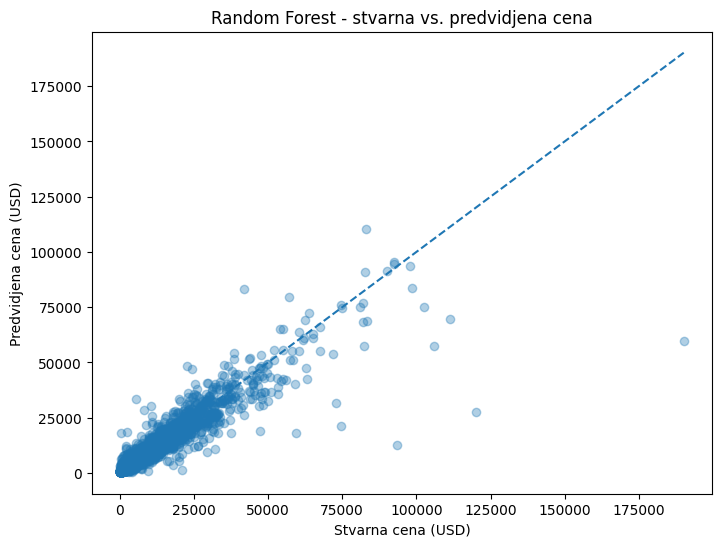

10 najvecih gresaka modela:


,make,model,car_age,mileage(kilometers),actual_price,predicted_price,absolute_error
6908,bentley,mulsanne,6,36500.0,190141,59552.02,130588.98
2821,bentley,mulsanne,9,178471.0,120000,27606.37,92393.63
4466,mercedes-benz,cl-amg,16,69652.0,93595,12799.43,80795.57
8181,lincoln,continental,43,27000.0,74500,21385.44,53114.56
4597,bmw,x5,1,7419.0,106000,57399.97,48600.03
4843,bmw,7-seriya,2,7900.0,111367,69747.96,41619.04
6765,bentley,continental-gt,7,73000.0,73000,31735.93,41264.07
9957,porsche,911,12,45000.0,59500,18279.11,41220.89
4228,toyota,tundra,2,13000.0,42000,83056.25,41056.25
1881,mercedes-benz,s-klass,29,64000.0,47400,18758.95,28641.05


In [17]:
# ------------------------------------------------------------
# STVARNA CENA VS. PREDVIDJENA CENA
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.35
)

min_price = min(
    y_test.min(),
    rf_predictions.min()
)

max_price = max(
    y_test.max(),
    rf_predictions.max()
)

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Stvarna cena (USD)")
plt.ylabel("Predvidjena cena (USD)")
plt.title("Random Forest - stvarna vs. predvidjena cena")

plt.show()


# ------------------------------------------------------------
# NAJVECE GRESKE
# ------------------------------------------------------------

worst_predictions = (
    prediction_examples
    .sort_values(
        "absolute_error",
        ascending=False
    )
    .head(10)
)

print("10 najvecih gresaka modela:")

display(
    worst_predictions[
        [
            "make",
            "model",
            "car_age",
            "mileage(kilometers)",
            "actual_price",
            "predicted_price",
            "absolute_error"
        ]
    ].round(2)
)

In [18]:
# ------------------------------------------------------------
# RANDOM FOREST SA LOG TRANSFORMACIJOM CILJNE PROMENLJIVE
# ------------------------------------------------------------

from sklearn.compose import TransformedTargetRegressor


log_rf_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            RandomForestRegressor(
                n_estimators=200,
                random_state=42,
                n_jobs=-1,
                max_depth=20,
                min_samples_leaf=2
            )
        )
    ]
)


log_rf_model = TransformedTargetRegressor(
    regressor=log_rf_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)


print("Treniranje Random Forest modela sa log transformacijom...")

log_rf_model.fit(
    X_train,
    y_train
)


# Predikcije nazad u USD
log_rf_predictions = log_rf_model.predict(
    X_test
)


# Evaluacija
log_rf_mae = mean_absolute_error(
    y_test,
    log_rf_predictions
)

log_rf_mse = mean_squared_error(
    y_test,
    log_rf_predictions
)

log_rf_rmse = np.sqrt(
    log_rf_mse
)

log_rf_r2 = r2_score(
    y_test,
    log_rf_predictions
)


print("\nRandom Forest + log target rezultati:")

print(
    "MAE:",
    round(log_rf_mae, 2)
)

print(
    "MSE:",
    round(log_rf_mse, 2)
)

print(
    "RMSE:",
    round(log_rf_rmse, 2)
)

print(
    "R2:",
    round(log_rf_r2, 4)
)

Treniranje Random Forest modela sa log transformacijom...

Random Forest + log target rezultati:
MAE: 1106.7
MSE: 8672931.15
RMSE: 2944.98
R2: 0.8708


In [19]:
# ------------------------------------------------------------
# FINALNO POREĐENJE MODELA
# ------------------------------------------------------------

final_model_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "Random Forest + Log Target"
    ],
    "MAE": [
        linear_mae,
        tree_mae,
        rf_mae,
        gb_mae,
        log_rf_mae
    ],
    "MSE": [
        linear_mse,
        tree_mse,
        rf_mse,
        gb_mse,
        log_rf_mse
    ],
    "RMSE": [
        linear_rmse,
        tree_rmse,
        rf_rmse,
        gb_rmse,
        log_rf_rmse
    ],
    "R2": [
        linear_r2,
        tree_r2,
        rf_r2,
        gb_r2,
        log_rf_r2
    ]
})

display(
    final_model_results
    .sort_values("MAE")
    .round({
        "MAE": 2,
        "MSE": 2,
        "RMSE": 2,
        "R2": 4
    })
)

print("\nFinalni izabrani model: Random Forest")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R2:", round(rf_r2, 4))

,Model,MAE,MSE,RMSE,R2
4,Random Forest + Log Target,1106.70,8672931.15,2944.98,0.8708
2,Random Forest,1108.31,8100920.74,2846.21,0.8793
1,Decision Tree,1325.65,11340819.26,3367.61,0.8310
3,Gradient Boosting,1538.81,9041896.28,3006.97,0.8653
0,Linear Regression,2086.24,18714231.20,4325.99,0.7212



Finalni izabrani model: Random Forest
MAE: 1108.31
RMSE: 2846.21
R2: 0.8793
